### Car Price Prediction Project

#### Objective : The goal of this project is to build a machine learning model that predicts the selling price of cars based on their features 

#### Problem Statement : Used car dealerships and buyers want to estimate the correct resale value of cars. An accurate price prediction system can help both sellers and buyers make better decisions. In this project, you are required to use data preprocessing, exploratory data analysis, and regression modeling to predict car prices.

### Step 1: Data Gathering And understanding

In [70]:
import pandas as pd 
path = r"C:\Users\Sakshi\Downloads\car_price_prediction.csv\car_price_prediction.csv"
df = pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


### Step2 :Basic Data quality checks

In [2]:
df.shape

(19237, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [4]:
df.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [5]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [6]:
df.duplicated().sum()

np.int64(313)

In [7]:
df = df.drop_duplicates()

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(18924, 18)

In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  str    
 3   Manufacturer      18924 non-null  str    
 4   Model             18924 non-null  str    
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  str    
 7   Leather interior  18924 non-null  str    
 8   Fuel type         18924 non-null  str    
 9   Engine volume     18924 non-null  str    
 10  Mileage           18924 non-null  str    
 11  Cylinders         18924 non-null  float64
 12  Gear box type     18924 non-null  str    
 13  Drive wheels      18924 non-null  str    
 14  Doors             18924 non-null  str    
 15  Wheel             18924 non-null  str    
 16  Color             18924 non-null  str    
 17  Airbags  

In [11]:
df = pd.get_dummies(df,columns=['Fuel type'],dtype=int)

In [12]:
updated = []
for i in df['Mileage']:
    data = i.split()
    updated.append(data[0])
updated = list(map(int,updated))
updated

[186005,
 192000,
 200000,
 168966,
 91901,
 160931,
 258909,
 216118,
 398069,
 128500,
 184467,
 0,
 350000,
 138038,
 76000,
 74146,
 121840,
 54317,
 295059,
 364523,
 112645,
 187000,
 39709,
 230000,
 0,
 210000,
 0,
 169000,
 158787,
 420550,
 180000,
 175056,
 200000,
 287274,
 250000,
 162000,
 10200,
 158000,
 103490,
 382746,
 203200,
 61057,
 11200,
 141000,
 160259,
 239342,
 128000,
 100734,
 141500,
 147000,
 87768,
 264014,
 132542,
 1600,
 87000,
 260000,
 5323,
 87112,
 204318,
 22000,
 83000,
 170000,
 312118,
 130000,
 200279,
 719847,
 154672,
 110969,
 225510,
 210000,
 148105,
 255456,
 111643,
 84506,
 288000,
 75000,
 94362,
 175000,
 263190,
 193614,
 264877,
 27656,
 16000,
 0,
 195053,
 121362,
 69191,
 83000,
 40772,
 172000,
 433811,
 350000,
 148213,
 103246,
 105394,
 160000,
 333333,
 0,
 214000,
 123346,
 80827,
 64464,
 91760,
 275240,
 300000,
 318400,
 91200,
 137802,
 151586,
 107000,
 210408,
 100567,
 86000,
 122740,
 144000,
 150000,
 100000,
 1

In [13]:
df['Mileage'] = updated
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 18924, dtype: int64

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18924 non-null  int64  
 1   Price                     18924 non-null  int64  
 2   Levy                      18924 non-null  str    
 3   Manufacturer              18924 non-null  str    
 4   Model                     18924 non-null  str    
 5   Prod. year                18924 non-null  int64  
 6   Category                  18924 non-null  str    
 7   Leather interior          18924 non-null  str    
 8   Engine volume             18924 non-null  str    
 9   Mileage                   18924 non-null  int64  
 10  Cylinders                 18924 non-null  float64
 11  Gear box type             18924 non-null  str    
 12  Drive wheels              18924 non-null  str    
 13  Doors                     18924 non-null  str    
 14  Wheel                 

### Step 3: EXploratory data Analysis(EDA)

In [15]:
# Descriptive statistics
df.describe().apply(lambda x: x.apply('{:.2f}'.format))

,ID,Price,Prod. year,Mileage,Cylinders,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
count,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00
mean,45575381.03,18587.44,2010.91,1555372.72,4.58,6.57,0.02,0.21,0.19,0.00,0.05,0.53,0.00
std,937546.82,192135.63,5.67,48802205.32,1.20,4.32,0.16,0.41,0.39,0.01,0.21,0.50,0.07
min,20746880.00,1.00,1939.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,45695007.50,5331.00,2009.00,70195.75,4.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,45771914.50,13172.00,2012.00,126400.00,4.00,6.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
75%,45801742.25,22063.00,2015.00,189119.75,4.00,12.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
max,45816654.00,26307500.00,2020.00,2147483647.00,16.00,16.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


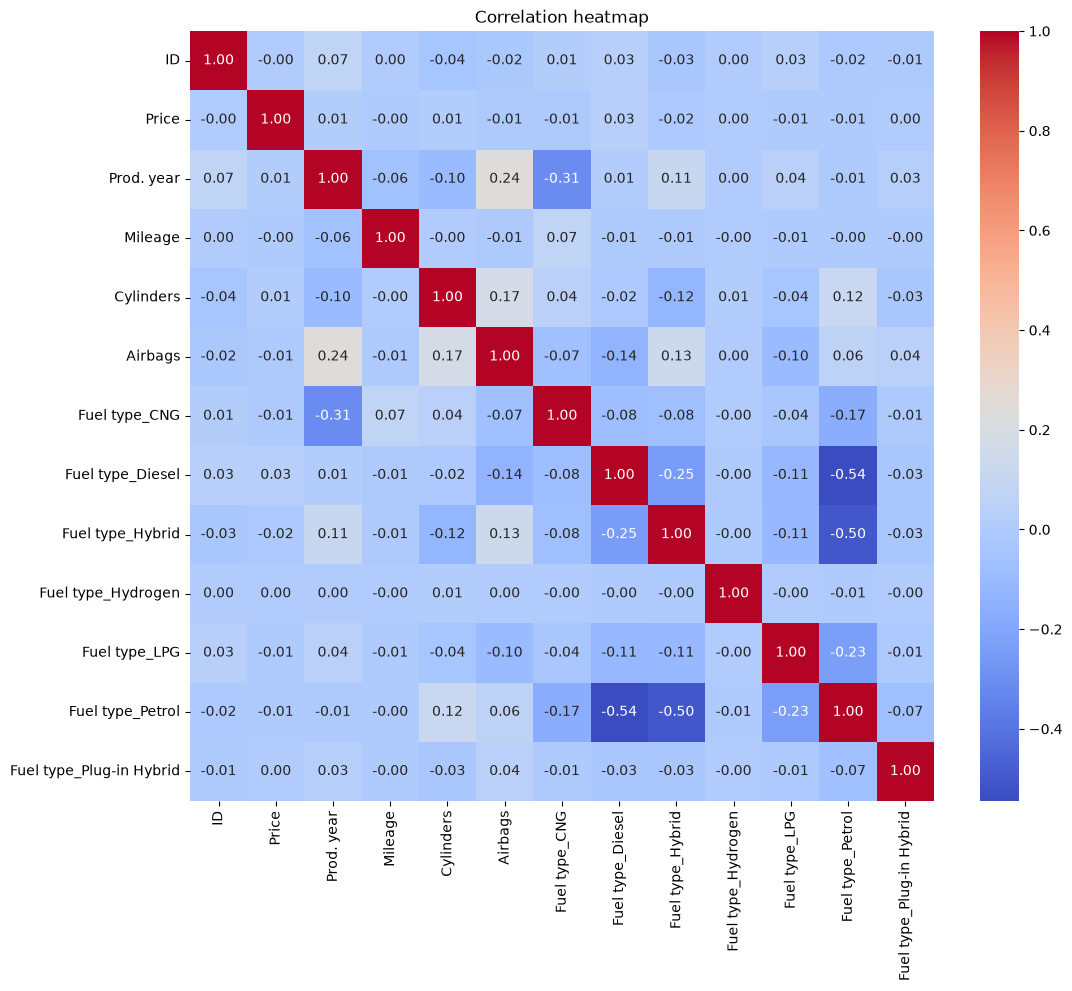

In [16]:
## Correlation 

import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

**Analysis**
-  strong correlation is observed between the selected features.
- Most features show weak or negligible linear relationships with each other.
- No significant relationship is observed among the numerical variables.
- The features may still have non-linear relationships that correlation cannot capture.

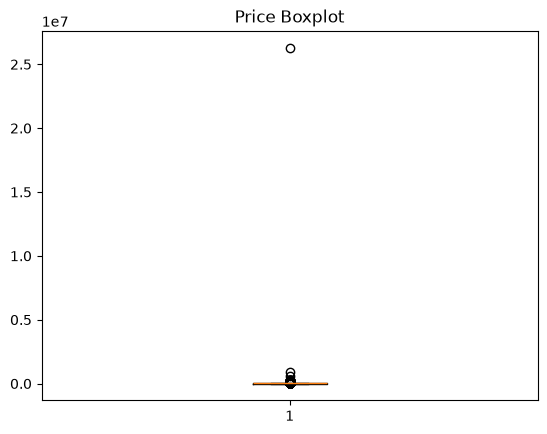

In [72]:
# Boxplot
import matplotlib.pyplot as plt

plt.boxplot(df["Price"])
plt.title("Price Boxplot")
plt.show()

**Analysis**
- Median: Most car prices are concentrated near the bottom of the graph.
- Spread: Prices have a wide range, with a few extremely high values.
- Outliers: Several outliers are present, including one around 26 million.

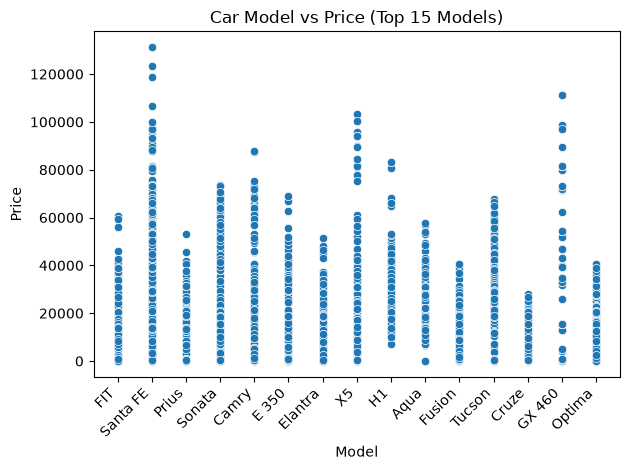

In [73]:
## Scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

top_models = df["Model"].value_counts().head(15).index

data = df[df["Model"].isin(top_models)]

sns.scatterplot(data=data, x="Model", y="Price")

plt.xticks(rotation=45, ha="right")
plt.title("Car Model vs Price (Top 15 Models)")
plt.tight_layout()
plt.show()

**Analysis**
- Price range: Prices vary widely across car models.
- Highest prices: Santa Fe, X5, and GX 460 have some high-priced cars.
- Price variation: Santa Fe, Camry, and X5 show considerable price variation.
- Outliers: Some unusually high prices need investigation.

In [19]:
# Clean levy and Engine Value
import pandas as pd
import numpy as np

# Clean Levy
df["Levy"] = df["Levy"].replace("-", np.nan)
df["Levy"] = pd.to_numeric(df["Levy"], errors="coerce")

# Clean Engine volume
df["Engine volume"] = (
    df["Engine volume"]
    .str.replace(" Turbo", "", regex=False)
)

df["Engine volume"] = pd.to_numeric(
    df["Engine volume"], errors="coerce"
)

print(df[["Levy", "Engine volume"]].dtypes)
print(df[["Levy", "Engine volume"]].isnull().sum())

Levy             float64
Engine volume    float64
dtype: object
Levy             5709
Engine volume       0
dtype: int64


In [20]:
# Fill missing Levy values with the median
df["Levy"] = df["Levy"].fillna(df["Levy"].median())

# Check missing values
print(df["Levy"].isnull().sum())

0


In [ ]:
# To identify the 10 most expensive cars
df.nlargest(10, 'Price')[['Manufacturer', 'Model', 'Prod. year', 'Price']]

,Manufacturer,Model,Prod. year,Price
16983,OPEL,Combo,1999,26307500
8541,LAMBORGHINI,Urus,2019,872946
1225,MERCEDES-BENZ,G 65 AMG 63AMG,2020,627220
5008,PORSCHE,911,2016,308906
9367,MERCEDES-BENZ,AMG GT S,2015,297930
14839,LAND ROVER,Range Rover Vogue,2019,297930
7749,BMW,M5 Машина в максимально,2018,288521
10759,LEXUS,LX 570,2018,260296
5840,MERCEDES-BENZ,GLE 400 A M G,2016,254024
15283,MERCEDES-BENZ,GLE 400,2017,250574


In [ ]:
# To find car record with highest price
df[df['Price'] == df['Price'].max()]

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Engine volume,Mileage,...,Wheel,Color,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
16983,45812886,26307500,781.0,OPEL,Combo,1999,Goods wagon,No,1.7,99999,...,Left wheel,Blue,0,0,1,0,0,0,0,0


In [ ]:
# Highest car price
print("Maximum Price:", df['Price'].max())
# Highest Levy value
print("Maximum Levy:", df['Levy'].max())

print("\nHighest Price records:")
display(
    df.nlargest(10, 'Price')[
        ['ID', 'Manufacturer', 'Model', 'Prod. year', 'Price', 'Levy']
    ]
)

Maximum Price: 26307500
Maximum Levy: 11714.0

Highest Price records:


,ID,Manufacturer,Model,Prod. year,Price,Levy
16983,45812886,OPEL,Combo,1999,26307500,781.0
8541,45761204,LAMBORGHINI,Urus,2019,872946,2067.0
1225,45795524,MERCEDES-BENZ,G 65 AMG 63AMG,2020,627220,781.0
5008,45810285,PORSCHE,911,2016,308906,1694.0
9367,45229113,MERCEDES-BENZ,AMG GT S,2015,297930,781.0
14839,45792307,LAND ROVER,Range Rover Vogue,2019,297930,781.0
7749,45760644,BMW,M5 Машина в максимально,2018,288521,2269.0
10759,45291161,LEXUS,LX 570,2018,260296,781.0
5840,44991441,MERCEDES-BENZ,GLE 400 A M G,2016,254024,1292.0
15283,45069516,MERCEDES-BENZ,GLE 400,2017,250574,1481.0


In [75]:
print("Cars priced above 300,000:", (df['Price'] > 300000).sum())

print("\nCars priced above 1,000,000:")
display(
    df[df['Price'] > 1000000][
        ['ID', 'Manufacturer', 'Model', 'Prod. year', 'Price']
    ]
)

Cars priced above 300,000: 4

Cars priced above 1,000,000:


,ID,Manufacturer,Model,Prod. year,Price
16983,45812886,OPEL,Combo,1999,26307500


In [45]:
df_test = df[df['ID'] != 16983].copy()

print("Original dataset:", df.shape)
print("Dataset after removing record:", df_test.shape)

Original dataset: (18924, 24)
Dataset after removing record: (18924, 24)


In [76]:
df_test = df[df['ID'] != 16983].copy()

In [77]:
df_test = df[df['Price'] != df['Price'].max()].copy()

print("Original dataset:", df.shape)
print("Dataset after removing record:", df_test.shape)

Original dataset: (19237, 18)
Dataset after removing record: (19236, 18)


In [48]:
print(df_test['Price'].max())

872946


###  Separate X and Y Feature

In [78]:
X = df_test.drop(columns=['ID', 'Price'])
Y = df_test[['Price']]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (19236, 16)
Y shape: (19236, 1)


### Step 3: Split the Data into Training or Testing 

In [79]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X, Y, train_size=0.75, random_state=42
)

print("X Train:", xtrain.shape)

print("X Test:", xtest.shape)
print("Y Train:", ytrain.shape)
print("Y Test:", ytest.shape)

X Train: (14427, 16)
X Test: (4809, 16)
Y Train: (14427, 1)
Y Test: (4809, 1)


In [81]:
# Identify Categorical and numerical columns
cat = list(xtrain.select_dtypes(
    include=['object', 'str', 'category']
).columns)

con = list(xtrain.select_dtypes(
    include='number'
).columns)

print("Categorical columns:", cat)
print("Numerical columns:", con)

Categorical columns: ['Levy', 'Manufacturer', 'Model', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color']
Numerical columns: ['Prod. year', 'Cylinders', 'Airbags']


### Step 4: Data Preprocessing  And Data Cleaning

In [84]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical pipeline
num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

# Categorical pipeline
cat_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False)
)

# Combine both pipelines
pre = ColumnTransformer([
    ('cat', cat_pipe, cat),
    ('con', num_pipe, con)
]).set_output(transform='pandas')

# Fit and transform training data
pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

print("Training data:", xtrain_pre.shape)
print("Testing data:", xtest_pre.shape)

Training data: (14427, 8295)
Testing data: (4809, 8295)


In [85]:
pre.fit(xtrain)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [86]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)


In [87]:
print(xtrain_pre.shape)
print(xtest_pre.shape)

(14427, 8295)
(4809, 8295)


### Step 5:  Model Building 

### Algorithm Evolution

In [57]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Create models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=21),
    'Random Forest': RandomForestRegressor(random_state=21),
    'Gradient Boosting': GradientBoostingRegressor(random_state=21),
    'XGBoost': XGBRegressor(random_state=21)
}

results = {}

# Train and evaluate models
for name, model in models.items():

    model.fit(xtrain_pre, np.ravel(ytrain))

    ypred = model.predict(xtest_pre)

    r2 = r2_score(np.ravel(ytest), ypred)
    mae = mean_absolute_error(np.ravel(ytest), ypred)
    rmse = np.sqrt(mean_squared_error(np.ravel(ytest), ypred))

    results[name] = {
        'R2 Score': r2,
        'MAE': mae,
        'RMSE': rmse
    }

# Display results
results_df = pd.DataFrame(results).T

print(results_df.round(2))

                   R2 Score      MAE      RMSE
Linear Regression      0.37  9113.93  14451.88
Decision Tree          0.52  5427.88  12636.20
Random Forest          0.68  4406.05  10281.24
Gradient Boosting      0.50  7686.37  12828.87
XGBoost                0.64  5816.77  10851.90


### Random Forest is the best model among the five models you tested.

### Hyperparameter Tunning 

In [60]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

rf = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    random_state=21,
    n_jobs=-1
)

rf.fit(xtrain_pre, ytrain.values.ravel())

y_pred = rf.predict(xtest_pre)

print("R2 Score:", r2_score(ytest, y_pred))
print("MAE:", mean_absolute_error(ytest, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(ytest, y_pred)))

R2 Score: 0.6540854043500859
MAE: 5018.742918938421
RMSE: 10685.027934469219


In [61]:
print(models.keys())

dict_keys(['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost'])


In [62]:
best_model = models['Random Forest']

In [65]:
from sklearn.ensemble import RandomForestRegressor

best_model = RandomForestRegressor(random_state=21, n_jobs=1)

best_model.fit(xtrain_pre, ytrain.values.ravel())

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",21
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"ma

In [66]:
ytest_pred = best_model.predict(xtest_pre)

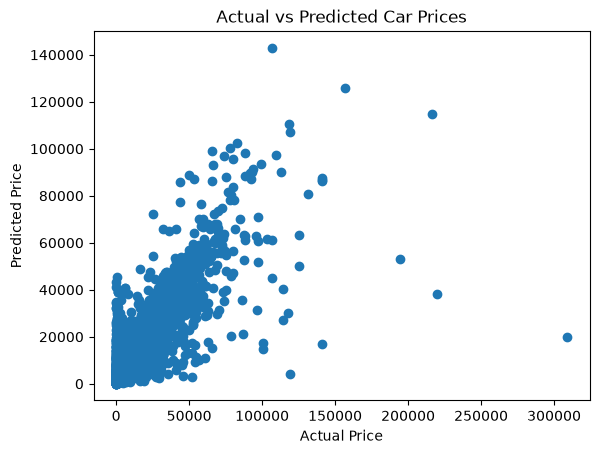

In [67]:
## Actual vs Predicted Plot

import matplotlib.pyplot as plt

plt.scatter(ytest, ytest_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

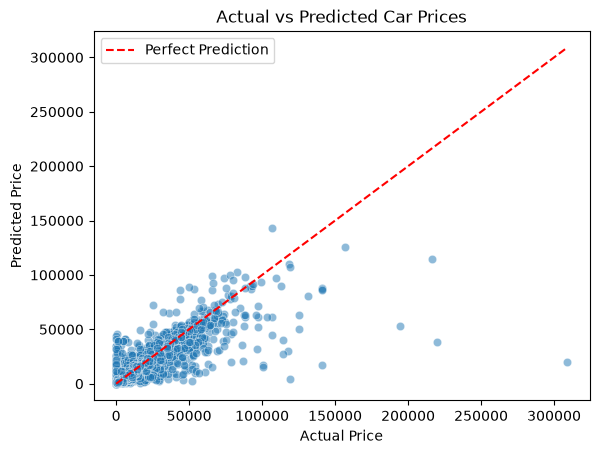

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=ytest.values.ravel(), y=ytest_pred, alpha=0.5)

plt.plot(
    [0, ytest.max().iloc[0]],
    [0, ytest.max().iloc[0]],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.legend()
plt.show()

**Analysis**
- 1. Most points are concentrated near the bottom-left.
- 2. The model performs better for some lower-priced cars.
- 3. Expensive cars are often underpredicted.
- 4. The model struggles to predict some expensive cars.

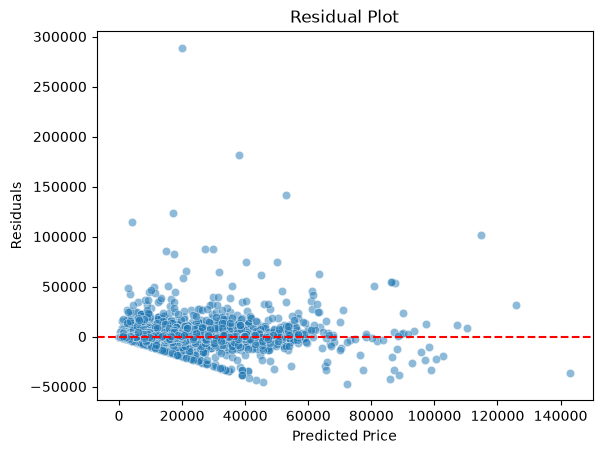

In [ ]:
## Residual plot(To identify errors)
import seaborn as sns
import matplotlib.pyplot as plt

residuals = ytest.values.ravel() - ytest_pred

sns.scatterplot(x=ytest_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

**Analysis**
- Points near zero indicate smaller prediction errors.
- Positive residuals mean the model underpredicts prices.
- Negative residuals mean the model overpredicts prices.
- Some points have very large errors, especially for certain expensive cars

### Step 6: Final Deliverables

- Data Gathering: Collected used-car data.
- Data Cleaning: Handled missing values and corrected data types.
- EDA: Analyzed price distributions and investigated outliers.
- Feature Selection: Selected car features as inputs and Price as the target.
- Preprocessing: Encoded categorical features and scaled numerical features.
- Train-Test Split: Divided data into training and testing sets.
- Model Training: Trained and compared five regression models.
- Model Evaluation: Evaluated models using R², MAE, and RMSE.
- Best Model: Random Forest achieved an R² score of 0.68.

In [88]:
import joblib

# Save the trained model
joblib.dump(best_model, "car_price_model.joblib")

# Save the preprocessing pipeline
joblib.dump(pre, "preprocessor.joblib")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
